## <span style="color:#eed699">Quest 2: Hitomezashi Sashiko Floorplan</span>

![Header image](./images/q3_header_image.svg)
[<img src="./images/instagram.svg" alt="My SVG" width="25" height="25">
<span style="color:lime">Monika Lipińska</span>](https://www.instagram.com/monli_art/)

### <span style="color:#eed699">Part I</span>

> ## <span style="color:#eed699"> <img src='./images/book.svg' height=40 width=40 style="display:inline-block height:fit-content;vertical-align: middle; margin: 5px; ">Story section</span>
>
> Your last chance to earn a pouch of coins is a project to replace the floor tiles throughout the castle. The algorithm should be elegant, and the patterns should be original and unique, while also reflecting the Kingdom and the royal family in some way.
>
> A distant childhood memory suddenly comes back to you: the summer holidays you spent at your grandparents' cottage. One evening, your grandmother noticed you passing the time by converting decimal numbers into binary. She hurried to her little craft cupboard, where she kept all sorts of sewing supplies, sat down beside you, and began stitching your answers onto a plain pillowcase. A few days later, she handed you the finished pillow, decorated with a remarkably intricate pattern.
>
> "This is your knowledge, my dear," she said. "Right now it may seem ordinary, or even a little boring, but one day you'll discover how to use it to create truly amazing things."
>
> The technique your grandmother used to turn ordinary binary numbers into a two-dimensional pattern is called <a href="https://www.youtube.com/watch?v=JbfhzlMk2eY" style="color:lime">Hitomezashi Sashiko Stitch Pattern<img src="./images/youtube-svgrepo-com.svg" alt="Youtube svg" width="40" height="40"  width="40" height="40" style="display:inline-block;width:2em;height:1em;vertical-align: middle;"/></a>.
>
> Starting from binary sequences (or... anything else), it creates intricate stitched patterns by following a small set of simple rules. It seems perfectly suited to a royal floor tiling project!
>
> <br/>
> Each floor section has a given ` width ` and ` height `, measured in tiles. For each pattern, you also have to prepare two sequences: ` horizontal-offsets ` and ` vertical-offsets `. Together, these values form the stitch pattern plan <span style="color:#eed699">( your notes )</span>.

**For each horizontal stitch line**, use the next digit from `horizontal-offsets`. If the digit is `0`, the first stitch starts immediately. If the digit is `1`, the first stitch is shifted by one tile. After that, stitches are placed every second tile. If a sequence is shorter than the floor size, repeat it from the beginning as many times as needed.

**For each vertical stitch line**, use the next digit from `vertical-offsets`. The rule is the same: `0` means no shift, and `1` means the stitches are shifted by one tile. You can repeat the sequence as many times as you need.

Once all stitches are placed, they divide the floor into many regions. Occasionally, a single tile becomes isolated. **A tile is considered isolated if it is surrounded by stitches on all four sides**. These tiles will be the special pieces in your pattern. They will be made from polished moonstone, and each one will be engraved with the name of someone from the royal family, along with a short note about that person. However, you want to **check how many isolated tiles appear in the final pattern**.

**Example based on the following notes:**

<pre style="border: 2px dotted lime;border-radius: 5px;padding:1rem;width: max-content;">
width=30
height=10
horizontal-offsets=10011
vertical-offsets=11011
</pre>

Start by drawing a grid with `30` tiles in width and `10` tiles in height. Write the values from `horizontal-offsets` along the horizontal grid lines, and the values from `vertical-offsets` along the vertical grid lines. If an offset sequence is shorter than the number of lines, repeat it from the beginning as many times as necessary.

![Table 1](./images/q3_p1_table_1.svg)

Next, draw all horizontal stitches. Each horizontal line uses the corresponding value from the assigned horizontal-offset. An offset of `0` means the first stitch starts immediately, while `1` shifts the first stitch by one tile. Continue placing stitches every second tile until reaching the edge of the grid.

![Table 2](./images/q3_p1_table_2.svg)

Then draw all vertical stitches using the assigned vertical-offsets. Apply exactly the same rule: `0` starts immediately, while `1` shifts the first stitch by one tile. Continue placing stitches every second tile.

![Table 3](./images/q3_p1_table_3.svg)

Mark every isolated tile and count them.

![Table 4](./images/q3_p1_table_4.svg)

This pattern contains<code style="color:white"> 27</code> isolated tiles.

<span style="color:#eed699">How many isolated tiles appear in the final pattern?<span>


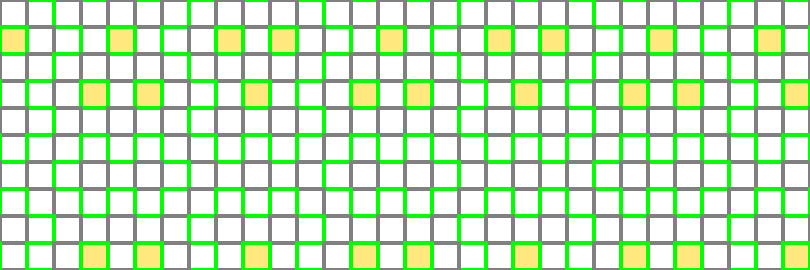

Test Example I passed, for partI.
Success


In [26]:
import re

import drawsvg as draw
from tabulate import tabulate
from test_utilities import test
from util import Str

test_cases = [
    # cSpell:disable
    {
        'name': 'Example I',
        'notes': """
            width=30
            height=10
            horizontal-offsets=10011
            vertical-offsets=11011
         """,
        'display': True,
        'save': 'part1_example1',
        'expected': 27,
    },
    # cSpell:enable
]

type Tile = tuple[int, int]


class Grid(Str):
    def __init__(self, notes: str) -> None:
        w, h, ho, vo = re.findall(r'\d+', notes)
        self.width = int(w)
        self.height = int(h)
        self.horizontal_offsets = ho
        self.vertical_offsets = vo

        self.horizontal = [
            [j & 1 == 0 if ho[i % len(ho)] == '0' else j & 1 == 1 for j in range(self.width)]
            for i in range(self.height + 1)
        ]
        self.vertical = [
            [i & 1 == 0 if vo[j % len(vo)] == '0' else i & 1 == 1 for i in range(self.height)]
            for j in range(self.width + 1)
        ]

    def get_isolated(self) -> set[Tile]:
        result = set()
        for i in range(self.height):
            for j in range(self.width):
                if (
                    self.horizontal[i][j]
                    and self.horizontal[i + 1][j]
                    and self.vertical[j][i]
                    and self.vertical[j + 1][i]
                ):
                    result.add((i, j))

        return result

    def display(self, group0: set[Tile], group1: set[Tile], save: str | None = None) -> None:
        cell_size = 27
        stroke_color_norm = 'grey'
        stroke_color_stitch = 'lime'
        fill_opacity = 0.5
        stroke_width = 4
        width, height = cell_size * self.width, cell_size * self.height
        d = draw.Drawing(width, height, origin=(0, 0))

        for i, j in group0:
            d.append(
                draw.Rectangle(
                    j * cell_size,
                    i * cell_size,
                    cell_size,
                    cell_size,
                    fill='green',
                    fill_opacity=fill_opacity,
                )
            )
        for i, j in group1:
            d.append(
                draw.Rectangle(
                    j * cell_size,
                    i * cell_size,
                    cell_size,
                    cell_size,
                    fill='gold',
                    fill_opacity=fill_opacity,
                )
            )

        # Draw horizontal lines
        for i in range(self.height + 1):
            y = i * cell_size
            for j in range(self.width):
                x = j * cell_size
                stroke_color = stroke_color_stitch if self.horizontal[i][j] else stroke_color_norm
                d.append(
                    draw.Line(
                        x,
                        y,
                        x + cell_size,
                        y,
                        stroke=stroke_color,
                        stroke_width=stroke_width,
                        stroke_linecap='round',
                    )
                )

        # Draw vertical lines
        for j in range(self.width + 1):
            x = j * cell_size
            for i in range(self.height):
                y = i * cell_size
                stroke_color = stroke_color_stitch if self.vertical[j][i] else stroke_color_norm
                d.append(
                    draw.Line(
                        x,
                        y,
                        x,
                        y + cell_size,
                        stroke=stroke_color,
                        stroke_width=stroke_width,
                        stroke_linecap='round',
                    )
                )

        if save is not None:
            d.save_svg(f'./output/{save}.svg')
        else:
            display(d)

    def __str__(self) -> str:
        return f'{tabulate(self.vertical, tablefmt="simple_grid")}'


@test(tests=test_cases[:1])
def partI(notes: str, display: bool = False, save: str | None = None) -> int:
    grid = Grid(notes)
    isolated = grid.get_isolated()
    if display:
        grid.display(group1=isolated, group0=set())
    if save is not None:
        grid.display(group1=isolated, group0=set(), save=save)
    return len(isolated)


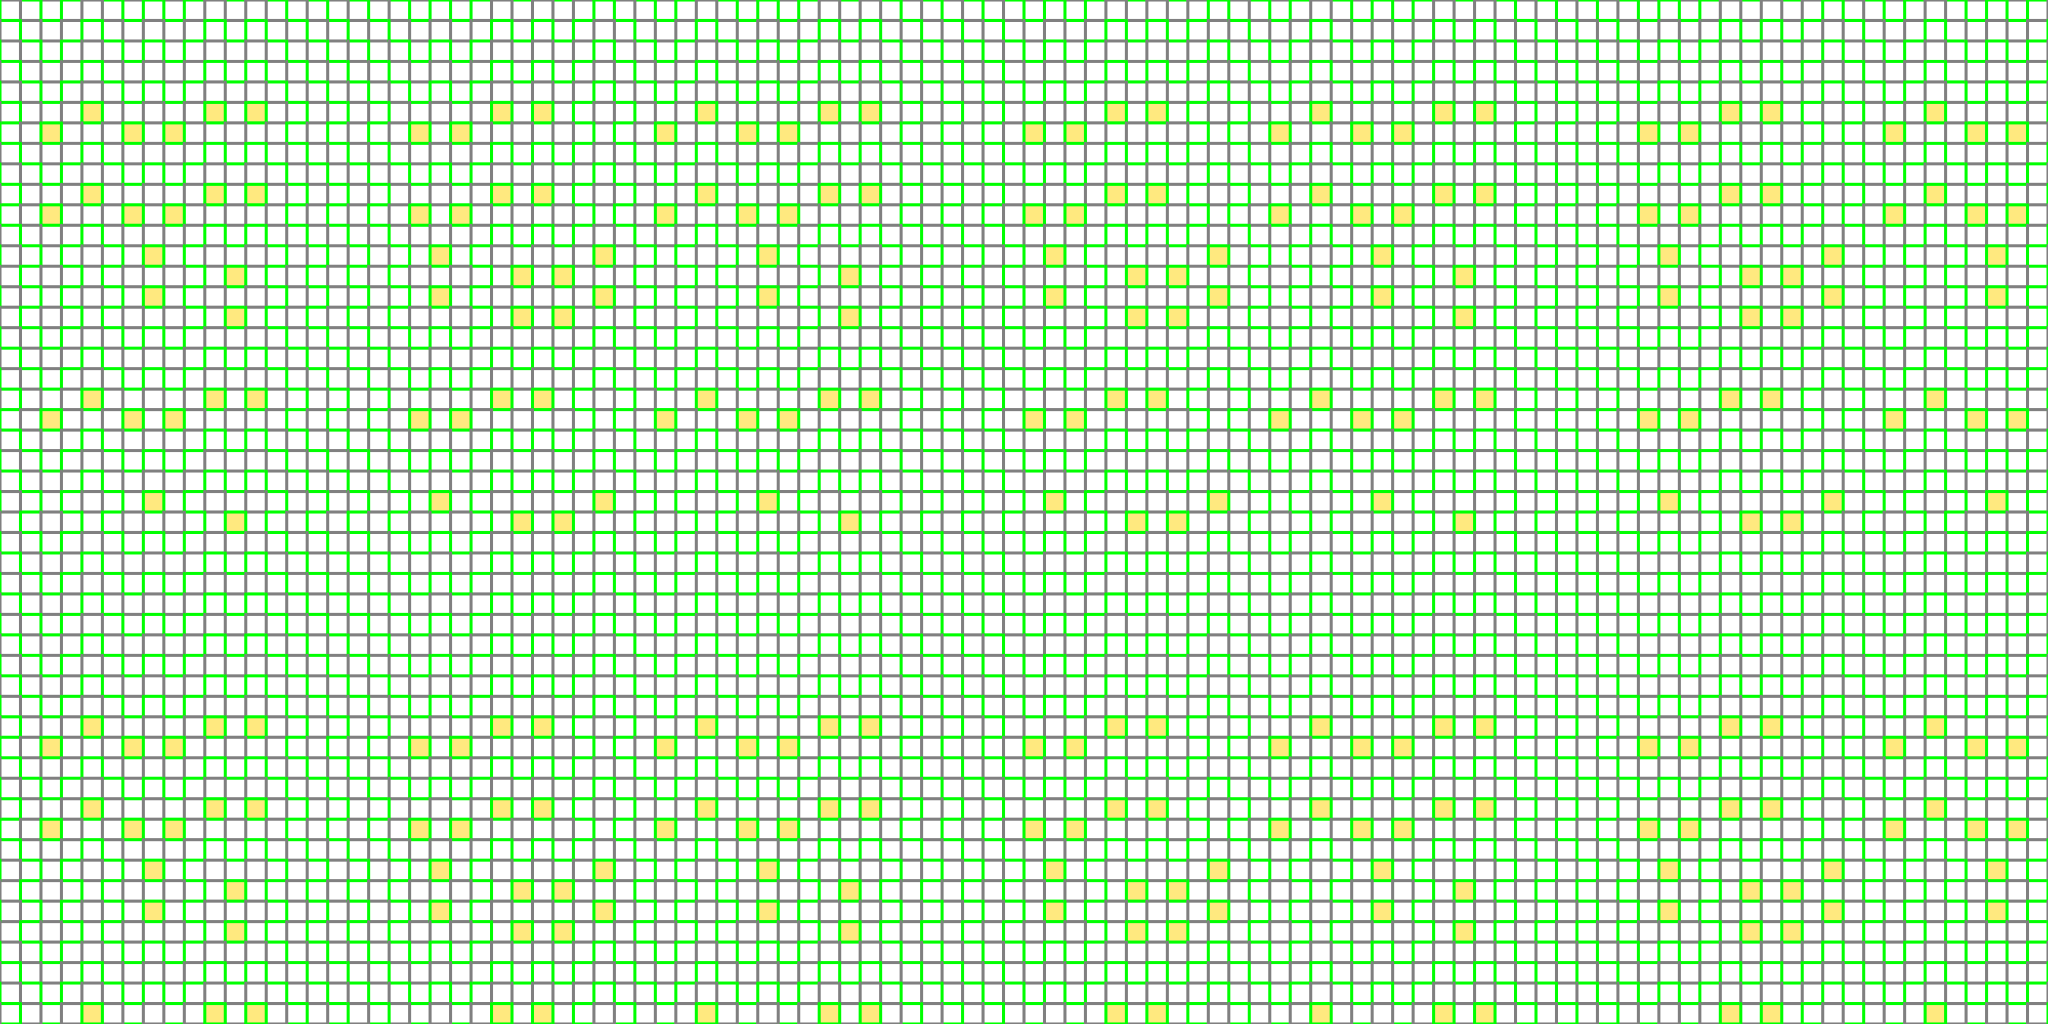

Part I: 281


In [27]:
with open('./inputs/everybody_codes_e4_q03_p1.txt') as f:
    notes1 = f.read()

print(f'Part I: {partI(notes1, display=True, save="part1")}')

## <span style="color:#eed699">Part II</span>

The pattern already looks quite impressive, but it still needs a little more character to secure the prize. It turns out that every region in any stitch pattern can be coloured using just two colours, so that no two neighbouring regions share the same colour.

Apply this colouring process to the new stitch pattern plan <span style="color:#eed699">( your notes )</span>. **The isolated tiles will naturally split into two colour groups as well**, which is even better! The smaller group can still be reserved for engravings honouring the royal family, while the larger one can celebrate members of the royal court, friends, distant relatives, knights, and other distinguished figures.

Once again, focus only on the isolated tiles - this time, only on **the larger of the two colour groups**.

**Example based on the following notes:**

<pre style="border: 2px dotted lime;border-radius: 5px;padding:1rem;width: max-content;">
width=30
height=10
horizontal-offsets=10011
vertical-offsets=11011
</pre>

Colouring the regions so that neighbouring regions always have different colours produces:

![table 1](./images/q3_p2_table_1.svg)

Colouring the regions so that neighbouring regions always have different colours produces:

![table 2](./images/q3_p2_table_2.svg)

Finally, identify the isolated tiles in each colour:

![table 3](./images/q3_p2_table_3.svg)

n this example, one group of isolated tiles contains `15` tiles, while the other contains `12`. The answer is simply the size of the larger group:<code style="color:whit"> 15</code>.

**Example based on the following notes:**

<pre style="border: 2px dotted lime;border-radius: 5px;padding:1rem;width: max-content;">
width=40
height=12
horizontal-offsets=11100
vertical-offsets=001101
</pre>

In this example, both groups of isolated tiles contain <code style="color:white"> 7</code> tiles, and the pattern looks like this:

![table 4](./images/q3_p2_table_4.svg)

<pre style="border: 2px dotted lime;border-radius: 5px;padding:1rem;width: max-content;">
width=100
height=70
horizontal-offsets=111101111101101111000100100110
vertical-offsets=110100001110111011101000001111
</pre>

In this example, the larger group of isolated tiles contains <code style="color:white"> 269</span> tiles, and the pattern looks like this:

![table 5](./images/q3_p2_table_5.svg)

<span style="color:#eed699">How many tiles are there in the larger group of isolated tiles?</span>


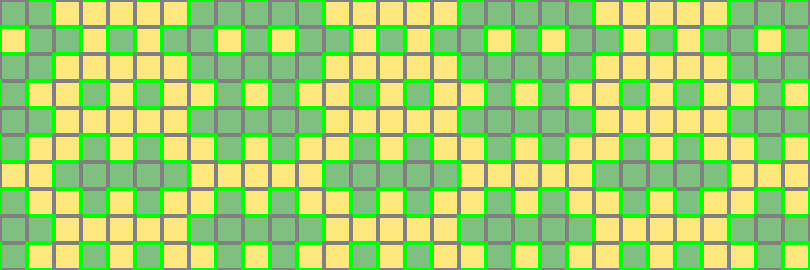

Test Example I passed, for partII.


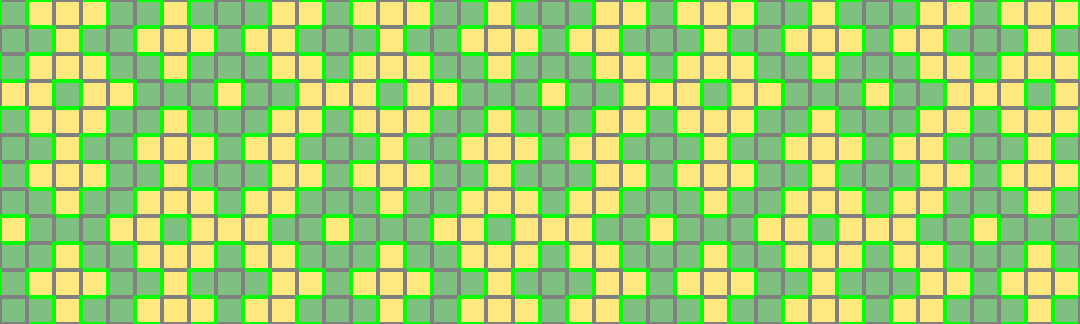

Test Example II passed, for partII.


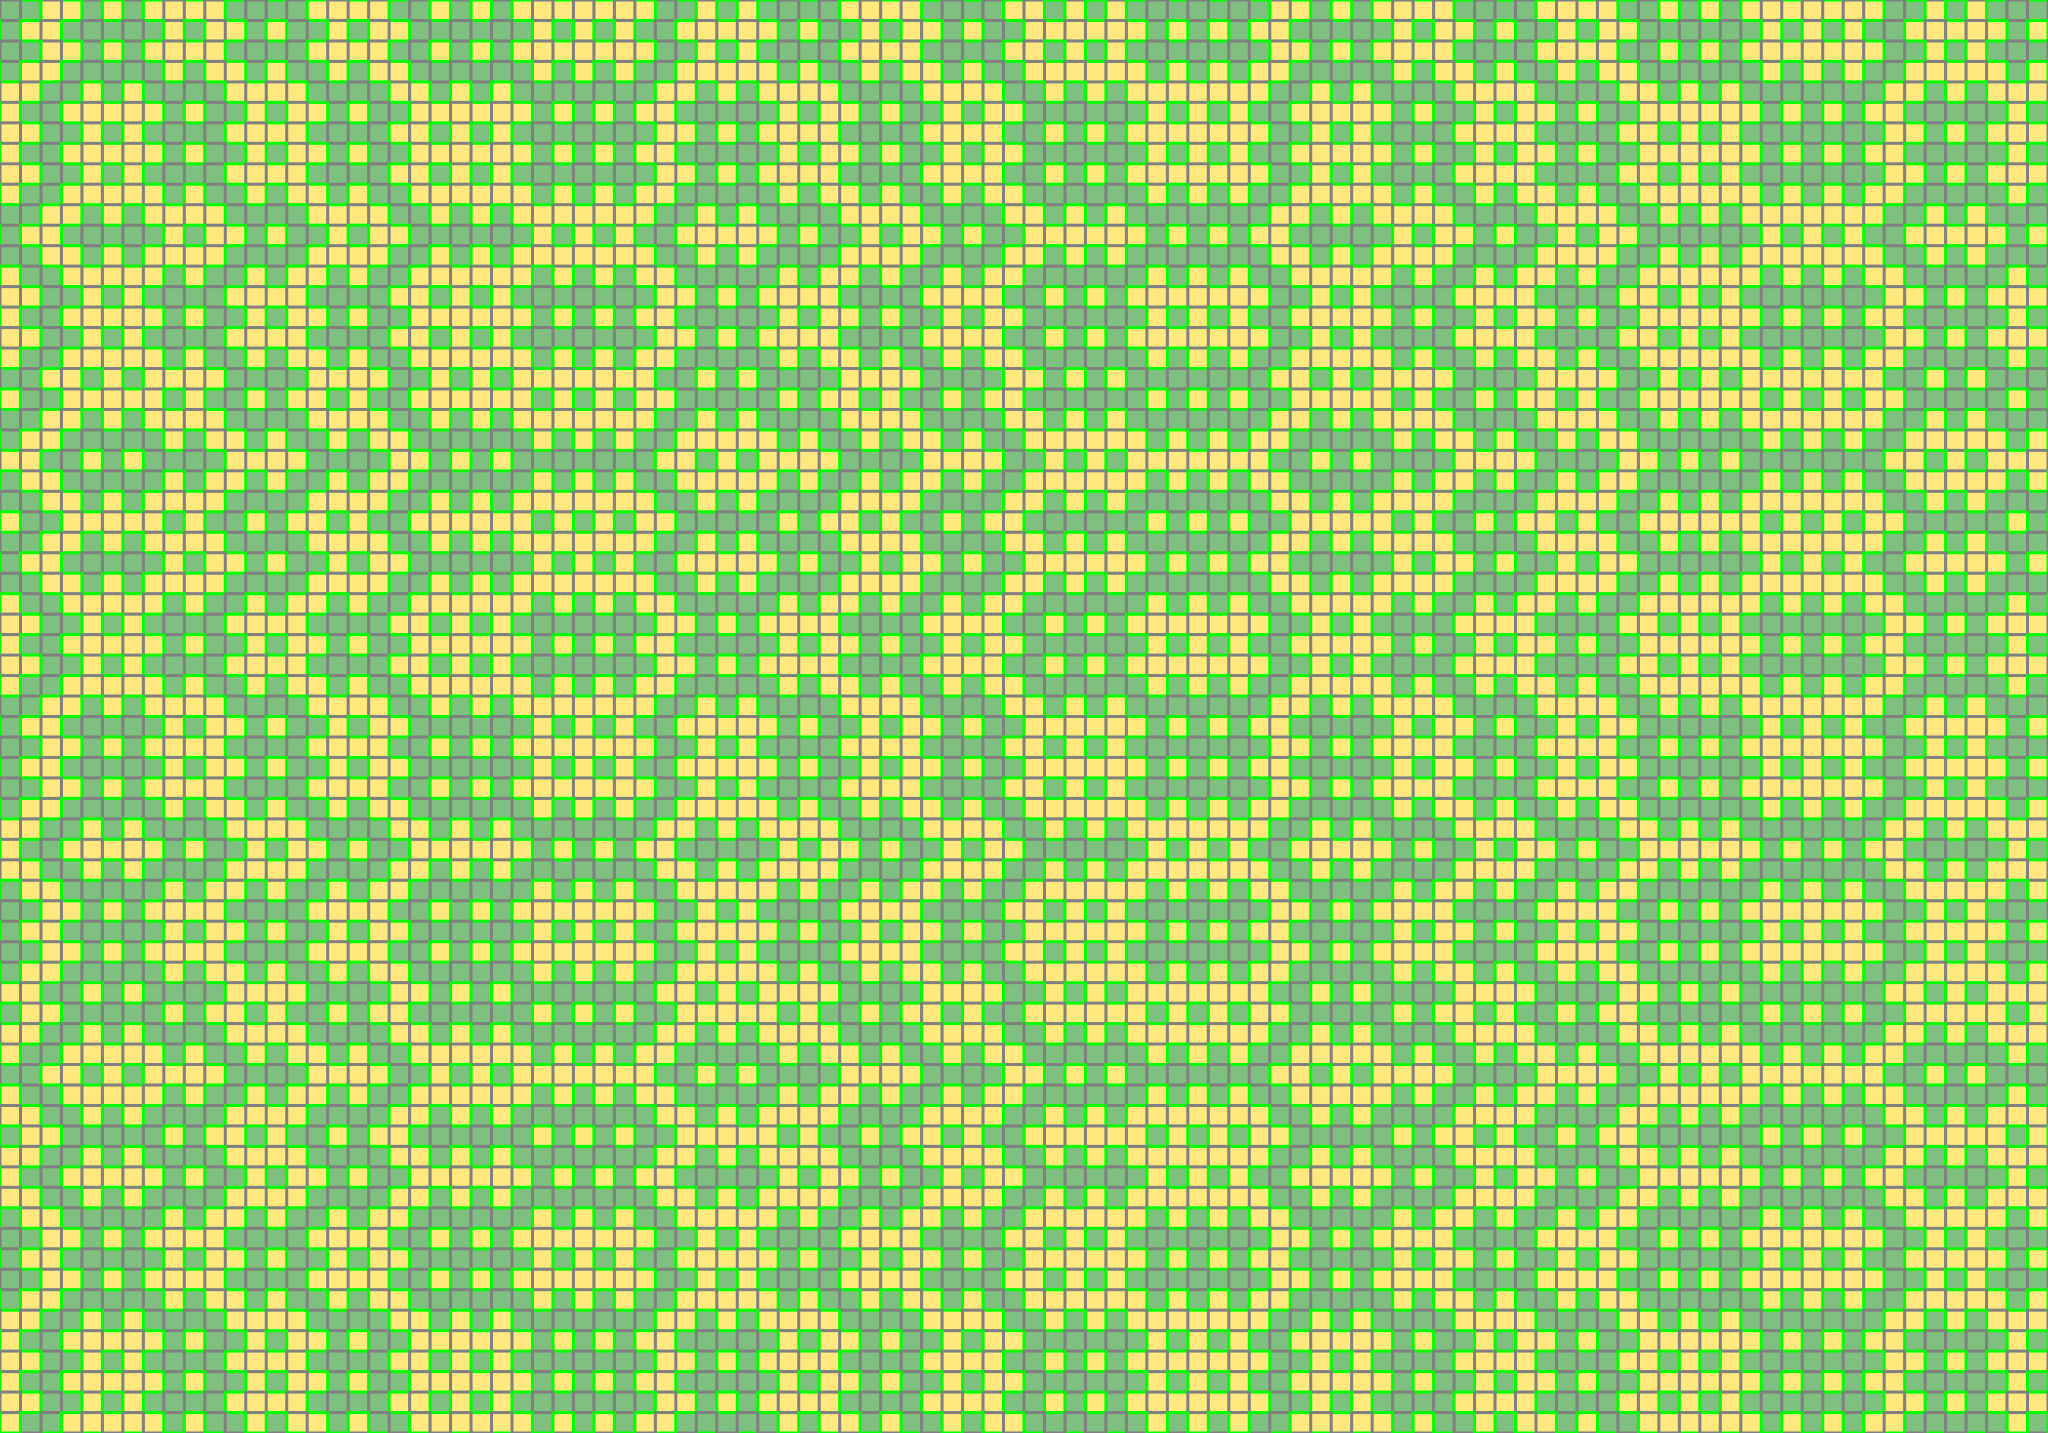

Test Example III passed, for partII.
Success


In [36]:
from collections import deque
from itertools import product

from test_utilities import test

test_cases = [
    # cSpell:disable
    {
        'name': 'Example I',
        'notes': """
            width=30
            height=10
            horizontal-offsets=10011
            vertical-offsets=11011
         """,
        'display': True,
        # 'save': 'part2_example1',
        'expected': 15,
    },
    {
        'name': 'Example II',
        'notes': """
            width=40
            height=12
            horizontal-offsets=11100
            vertical-offsets=001101
         """,
        'display': True,
        # 'save': 'part2_example2',
        'expected': 7,
    },
    {
        'name': 'Example III',
        'notes': """
            width=100
            height=70
            horizontal-offsets=111101111101101111000100100110
            vertical-offsets=110100001110111011101000001111
         """,
        'display': True,
        # 'save': 'part2_example3',
        'expected': 269,
    },
    # cSpell:enable
]


class GridII(Grid):
    AROUND = (-1, 0), (0, 1), (1, 0), (0, -1)

    def __init__(self, notes: str) -> None:
        super().__init__(notes)
        self.coloring = self.bi_coloring()

    def bi_coloring(self) -> list[list[int]]:
        grid = [[-1] * self.width for _ in range(self.height)]

        for i, j in product(range(self.height), range(self.width)):
            if grid[i][j] > -1:
                continue

            neighbor_groups = [
                grid[i + di][j + dj]
                for di, dj in self.AROUND
                if 0 <= i + di < self.height
                if 0 <= j + dj < self.width
                if grid[i + di][j + dj] > -1
            ]

            if neighbor_groups:
                first_value = neighbor_groups[0]

                assert all(item == first_value for item in neighbor_groups), (
                    f"Not all elements are the same. Expected '{first_value}', got {neighbor_groups}"
                )

                group = int(not first_value)
            else:
                group = 0
            queue = deque([(i, j)])

            while queue:
                ii, jj = queue.pop()

                if grid[ii][jj] > -1:
                    continue

                grid[ii][jj] = group

                for di, dj in self.AROUND:
                    if not 0 <= ii + di < self.height:
                        continue

                    if not 0 <= jj + dj < self.width:
                        continue

                    if di == -1 and self.horizontal[ii][jj]:
                        continue

                    if di == 1 and self.horizontal[ii + 1][jj]:
                        continue

                    if dj == -1 and self.vertical[jj][ii]:
                        continue

                    if dj == 1 and self.vertical[jj + 1][ii]:
                        continue

                    queue.append((ii + di, jj + dj))

        return grid

    def tiles_larger_group_isolated(self) -> int:
        isolated = self.get_isolated()
        group0, group1 = 0, 0
        for i, j in isolated:
            if self.coloring[i][j] == 0:
                group0 += 1
            else:
                group1 += 1

        return max(group0, group1)


@test(tests=test_cases[:])
def partII(notes: str, display: bool = False, save: str | None = None) -> int:
    grid = GridII(notes)

    if display:
        group0 = {
            (i, j)
            for j in range(grid.width)
            for i in range(grid.height)
            if grid.coloring[i][j] == 0
        }
        group1 = {
            (i, j)
            for j in range(grid.width)
            for i in range(grid.height)
            if grid.coloring[i][j] == 1
        }
        grid.display(group0=group0, group1=group1)
    if save is not None:
        group0 = {
            (i, j)
            for j in range(grid.width)
            for i in range(grid.height)
            if grid.coloring[i][j] == 0
        }
        group1 = {
            (i, j)
            for j in range(grid.width)
            for i in range(grid.height)
            if grid.coloring[i][j] == 1
        }
        grid.display(group0=group0, group1=group1, save=save)
    return grid.tiles_larger_group_isolated()


In [34]:
with open('./inputs/everybody_codes_e4_q03_p2.txt') as f:
    notes2 = f.read()


print(f'Part II: {partII(notes2)}')

Part II: 11407


## <span style="color:#eed699">Part III</span>


In [ ]:
# with open('./inputs/everybody_codes_e4_q03_p3.txt') as f:
#     notes3 = f.read()


# print(f'Part III: {partIII(notes3)}')

<div style="color:lime;width:25%;text-align:center">Quack yeah!</div>
<br/>

![happy quack](./images/happy_quack.svg)
